# 03 · EOS pressure, density, volume and fugacity

**Requirements:** SAFT/JAX and RDKit.

Run this notebook from top to bottom in the environment where ThermoWeave is installed. All examples are self-contained unless explicitly marked optional. See the [course index](../tutorials.md) and [theory guide](../theory.md).

<a class="md-button" href="03_saft_eos_properties.ipynb" download>Download notebook</a>


SAFT supplies $a^{res}=A^{res}/(nRT)$, not only liquid activity coefficients.
 Pressure follows $P=\rho RT[1+\rho(\partial a^{res}/\partial\rho)_{T,x}]$.
 Density solves that equation for a chosen branch. $v=1/\rho$ is molar volume.
 The following liquid and vapour examples are **separate state points**, not a
 demonstrated coexisting pair. Parameter sources: [Haslam et al.](https://doi.org/10.1021/acs.jced.0c00746).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import SAFTgammaMie
from thermoweave.saft.params import R
model = SAFTgammaMie.from_smiles({'water': 'O', 'ethanol': 'CCO'},
                               pressure_Pa=101325., report_assignment=False)
for T, P, x, phase in [(298.15, 101325., [0.8, 0.2], 'liquid'),
                       (360., 50000., [0.3, 0.7], 'vapor')]:
    rho = model.density(T, x, pressure_Pa=P, phase=phase)
    p_back = model.pressure(T, x, rho)
    print(f'{phase}: T={T} K; P={P:.1f} Pa; rho={rho:.5f} mol/m3; '
          f'Vm={1e6/rho:.5f} cm3/mol; Z={P/(rho*R*T):.6f}')
    print('  pressure round-trip error [Pa]:', p_back-P)
    print('  ln phi:', model.ln_fugacity_coefficients(T, x, P, phase=phase))
    np.testing.assert_allclose(p_back, P, rtol=1e-9, atol=1e-3)

liquid: T=298.15 K; P=101325.0 Pa; rho=39724.52676 mol/m3; Vm=25.17336 cm3/mol; Z=0.001029
  pressure round-trip error [Pa]: 3.0628012609668076e-05
  ln phi: [-3.38501763 -1.85316638]
vapor: T=360.0 K; P=50000.0 Pa; rho=16.97968 mol/m3; Vm=58893.92419 cm3/mol; Z=0.983793
  pressure round-trip error [Pa]: 2.1827872842550278e-11
  ln phi: [-0.02034516 -0.01440425]


## Inspect the free-energy contributions
 `residual_helmholtz_contributions` separates monomer, chain and association.
 These model terms sum to the residual Helmholtz energy; they are not separate
 experimentally measured energies. Fugacity coefficients are relative to an
 ideal-gas reference, while $\gamma_i$ uses the pure-liquid reference.

In [2]:
T, x = 298.15, np.array([0.8, 0.2])
rho = model.density(T, x)
parts = model.residual_helmholtz_contributions(T, x, rho)
print('Residual Helmholtz parts:', parts)
print('Unbonded site fractions:', model.non_bonded_site_fractions(T, x, rho))
np.testing.assert_allclose(sum(parts.values()), model.residual_helmholtz(T, x, rho))
lnphi = model.ln_fugacity_coefficients(T, x)
pure = model.ln_fugacity_coefficients_pure(T)
np.testing.assert_allclose(model.ln_activity_coefficients(T, x), lnphi-pure, atol=1e-12)
print('ln gamma:', model.ln_activity_coefficients(T, x))

Residual Helmholtz parts: {'association': -7.391542928470513, 'chain': -0.08994228464141532, 'monomer': -1.477419987079516}
Unbonded site fractions: [0.04198741 0.17248184 0.24865791 0.10235124]
ln gamma: [0.07061374 0.72796927]


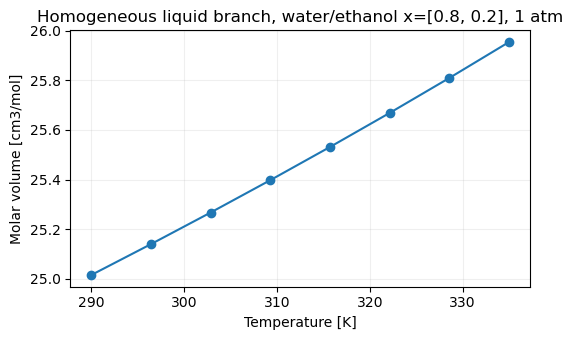

In [3]:
temperatures = np.linspace(290., 335., 8)
molar_volumes = [1e6/model.density(float(t), x) for t in temperatures]
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(temperatures, molar_volumes, 'o-')
ax.set(xlabel='Temperature [K]', ylabel='Molar volume [cm3/mol]',
       title='Homogeneous liquid branch, water/ethanol x=[0.8, 0.2], 1 atm')
ax.grid(alpha=0.2); fig.tight_layout(); plt.show()

**Try:** change pressure with `pressure_Pa=...` without rebuilding the model.
 Both branches can be metastable or cease to exist at some states. Use a phase
 stability/flash calculation when the phase assemblage matters. Absolute caloric
 properties also require ideal-gas reference contributions; notebook 04 computes
 residual/excess quantities explicitly.